# step5_rerank_calibration

**Owner:** P6  
**Purpose:** Tune how closely KLAR's top 10 matches a user's reading history, then evaluate the chosen weight on Test.  
**Inputs:** Step 1 candidate lists, click histories, and article topics, plus Step 4 KLAR scores.  
**Outputs:** The calibrated ranking for Step 6, result tables, one tuning figure, and an example slate.

Run the Colab setup, then run Sections 1–4 in order.

In [ ]:
# --- Colab setup: mount Drive and configure the shared project paths. ---
import os
from pathlib import Path
import subprocess
import sys

from google.colab import drive
import numpy as np
import pandas as pd

drive.mount("/content/drive")

# Choose the first shortcut that contains the processed datasets.
drive_shortcuts = (
    Path("/content/drive/MyDrive/BT4222_Project"),
    Path("/content/drive/MyDrive/BT4222 G4/BT4222_Project"),
)
data_root = next(
    (folder for folder in drive_shortcuts if (folder / "data" / "processed").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError(
        "No BT4222_Project shortcut with data/processed was found in MyDrive "
        "or MyDrive/BT4222 G4."
    )
os.environ["MIND_PROJECT_DIR"] = str(data_root)

# Load the repository helpers with the Drive path already set for config.
project_root = Path("/content/BT4222-Project-Group-4--MIND")
if not (project_root / "config.py").is_file():
    subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/Fdiannz/BT4222-Project-Group-4--MIND.git",
            str(project_root),
        ],
        check=True,
    )
sys.path.insert(0, str(project_root))

# Import project modules after configuring Drive and the checkout path.
import config
from utils.metrics import add_rank, attach_scores, topk

print("Data folder:", config.DATA_DIR)
print("Processed folder:", config.PROCESSED_DIR)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/BT4222_Project/data
Processed folder: /content/drive/MyDrive/BT4222_Project/data/processed


## 1. Inputs, relevance baseline, and calibration implementation

Build the original KLAR ranking and count the topics in each user's reading history. Calibration uses those counts to guide the top 10.

### 1.1 Input paths and settings

Use KLAR v1 scores from Step 4 and the candidate lists, histories, and article topics from Step 1. Tune tests weights from 0.0 to 0.8 in steps of 0.1.

In [ ]:
# --- 1.1: Configure input paths and shared ranking settings. ---
PROCESSED_DIR = Path(config.PROCESSED_DIR)
SCORES_DIR = Path(config.SCORES_DIR)
KEY_COLUMNS = ["impression_id", "news_id"]
COLD_COLUMN = "cold_article"
TOPIC_COLUMNS = ["category", "subcategory"]
CANDIDATE_COLUMNS = KEY_COLUMNS + ["label", COLD_COLUMN] + TOPIC_COLUMNS

INPUT_SPLITS = {
    "tune": PROCESSED_DIR / "tune_candidates.parquet",
    "eval": PROCESSED_DIR / "eval_candidates.parquet",
}
HISTORY_PATHS = {
    "tune": PROCESSED_DIR / "tune_impressions.parquet",
    "eval": PROCESSED_DIR / "eval_impressions.parquet",
}
NEWS_METADATA_PATH = PROCESSED_DIR / "news_metadata.parquet"

BASE_MODEL_NAME = "klar_v1"
TUNE_SCORES_PATH = SCORES_DIR / "step4_klar_tune.parquet"
EVAL_SCORES_PATH = SCORES_DIR / "step4_klar_eval.parquet"
SCORE_COLUMN = "score"
TOP_K, SEED = config.TOP_K, config.SEED
RELEVANCE_SCALING = "per_impression_minmax"
CALIBRATION_WEIGHTS = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8)
SELECTED_CALIBRATION_WEIGHT = 0.6
CATEGORY_WEIGHT = 0.75
SUBCATEGORY_WEIGHT = 0.25

print("Model:", BASE_MODEL_NAME, "| Top k:", TOP_K, "| Seed:", SEED)
print("Tuning scores:", TUNE_SCORES_PATH)
print("Evaluation scores:", EVAL_SCORES_PATH)

Model: klar_v1 | Top k: 10 | Seed: 42
Tuning scores: /content/drive/MyDrive/BT4222_Project/data/scores/step4_klar_tune.parquet
Evaluation scores: /content/drive/MyDrive/BT4222_Project/data/scores/step4_klar_eval.parquet


### 1.2 Load processed candidates, model scores, and histories

Load the complete Tune candidate lists and the reading histories linked to them.

#### 1.2.1 Define input readers

Check that each candidate has one usable KLAR score and that the history and topic records have unique IDs.

In [ ]:
# --- 1.2.1: Read processed candidates and join separately delivered scores. ---
def load_candidate_split(split):
    """Read the full processed split; cleaning and slate construction belong upstream."""
    return pd.read_parquet(INPUT_SPLITS[split], columns=CANDIDATE_COLUMNS, engine="pyarrow")


def load_scored_split(split, candidates):
    """Attach one original score per candidate using the shared strict join."""
    path = TUNE_SCORES_PATH if split == "tune" else EVAL_SCORES_PATH
    scores = pd.read_parquet(path, columns=KEY_COLUMNS + [SCORE_COLUMN], engine="pyarrow")
    scores = scores.rename(columns={SCORE_COLUMN: "score"})
    # This score artifact is separate from the already-cleaned candidate table.
    if not np.isfinite(scores["score"].to_numpy(dtype=np.float64)).all():
        raise ValueError("Model scores must be finite.")
    return attach_scores(candidates, scores)

# --- History and article-topic readers. ---
def load_impression_histories(split, candidate_impression_ids):
    histories = pd.read_parquet(
        HISTORY_PATHS[split], columns=["impression_id", "history"], engine="pyarrow"
    ).set_index("impression_id", verify_integrity=True)
    missing = pd.Index(candidate_impression_ids).difference(histories.index)
    if len(missing):
        raise ValueError(f"{split} is missing history rows for {len(missing):,} impressions.")
    return histories["history"].fillna("")


def load_news_topics():
    return pd.read_parquet(
        NEWS_METADATA_PATH, columns=["news_id"] + TOPIC_COLUMNS, engine="pyarrow"
    ).set_index("news_id", verify_integrity=True)

#### 1.2.2 Load complete tuning candidates

Load all candidates shown on the tuning day.

In [ ]:
# --- 1.2.2: Load the complete tuning candidate slates. ---
tune_candidates = load_candidate_split("tune")
print(f"Tuning candidates: {len(tune_candidates):,}")

Tuning candidates: 17,400,106


#### 1.2.3 Attach tuning model scores

Match KLAR scores to candidates by impression ID and article ID.

In [ ]:
# --- 1.2.3: Attach KLAR scores to the complete tuning slates. ---
tune_scored = load_scored_split("tune", tune_candidates)
del tune_candidates

#### 1.2.4 Load impression histories and article topics

Load the clicks recorded before each impression and the categories and subcategories of the articles.

In [ ]:
# --- 1.2.4: Load tuning histories and the shared article-topic lookup. ---
tune_histories = load_impression_histories("tune", tune_scored["impression_id"].unique())
news_topics = load_news_topics()
print(f"Tuning history rows: {len(tune_histories):,}")
print(f"Articles in topic lookup: {len(news_topics):,}")

Tuning history rows: 431,517
Articles in topic lookup: 104,151


### 1.3 Relevance-only baseline

Use the original KLAR order as the reference.

#### 1.3.1 Construct the original ranking and define eligibility

Rank each impression by KLAR score, with a fixed seed for ties. Calibration can change a list when it has more than ten candidates and a usable reading history.

In [ ]:
# --- 1.3.1a: Build a reproducible relevance-only reference from joined model scores. ---
def build_relevance_reference(scored, k=None, seed=None):
    """Return complete ranks, slate eligibility, and top-k lists from Section 1.2 inputs."""
    # Use the shared top-k and seed when the caller leaves them unspecified.
    k = TOP_K if k is None else k
    seed = SEED if seed is None else seed
    required = CANDIDATE_COLUMNS + ["score"]

    # Canonical ordering makes seeded tie draws independent of input row order.
    # Keep only the fields needed downstream to limit extra copies of the large table.
    canonical = scored[required].sort_values(KEY_COLUMNS, kind="stable").reset_index(drop=True)
    ranked = add_rank(canonical, "score", rank_col="baseline_rank", seed=seed)
    del canonical

    # Determine eligibility from the full slate, never from a truncated top-k list.
    slates = ranked.groupby("impression_id", sort=False).size().rename("n_candidates").to_frame()
    slates["rerank_eligible"] = slates["n_candidates"].gt(k)
    ranked["rerank_eligible"] = ranked["impression_id"].map(slates["rerank_eligible"])

    # Pre-filter by known rank before using the shared top-k helper to avoid sorting
    # millions of candidates that cannot appear in the displayed reference lists.
    top = topk(ranked.loc[ranked["baseline_rank"].le(k)], "baseline_rank", k=k)
    return ranked, slates, top

In [ ]:
# --- 1.3.2: Build the Tune relevance reference. ---
tune_baseline_ranked, tune_slates, tune_baseline_top = build_relevance_reference(tune_scored)
del tune_scored
print(f"Impressions with more than {TOP_K} candidates: {tune_slates['rerank_eligible'].sum():,}")

Impressions with more than 10 candidates: 337,656


### 1.4 Greedy calibration implementation

Fill the top 10 one article at a time. Each choice balances KLAR relevance with how closely the new list matches the user's past reading.

#### 1.4.1 Relevance scaling and numerical conventions

Rescale KLAR scores from 0 to 1 within each impression. At each position, choose the article with the highest score:

`(1 - alpha) * relevance - alpha * (0.75 * category JSD + 0.25 * subcategory JSD)`

Jensen–Shannon divergence (JSD) measures the difference between the user's historical topic mix and the mix after adding an article. Zero means the mixes are identical. A larger alpha gives topic matching more weight, and broad categories count three times as much as subcategories.

In [ ]:
# --- 1.4.1: Define score scaling and Jensen-Shannon divergence. ---
def scale_calibration_relevance(scores):
    """Min-max scale the complete slate without changing the original scores."""
    low, high = scores.min(), scores.max()
    if high == low:
        return np.zeros_like(scores)
    return (scores - low) / (high - low)


def _xlog2x(values):
    """Compute x log2(x), with a zero contribution at x = 0."""
    logs = np.zeros_like(values, dtype=float)
    np.log2(values, out=logs, where=values > 0)
    return values * logs


def _js_contribution(target, observed):
    """Return the per-topic terms whose sum is base-2 JSD."""
    combined = target + observed
    return 0.5 * (_xlog2x(target) + _xlog2x(observed) - _xlog2x(combined) + combined)


def jensen_shannon_divergence(target, observed):
    """Compare two topic distributions over their union of topic labels."""
    topics = dict.fromkeys((*target, *observed))
    target_values = np.array([target.get(topic, 0.0) for topic in topics])
    observed_values = np.array([observed.get(topic, 0.0) for topic in topics])
    return float(_js_contribution(target_values, observed_values).sum())


def _topic_addition_cost(target, counts, next_size):
    """Compute the change in JSD contribution from one additional item per topic."""
    before = counts / next_size
    after = (counts + 1) / next_size
    # The target-only term cancels. The remaining linear change is one item.
    return 0.5 * (
        _xlog2x(after) - _xlog2x(before)
        - _xlog2x(target + after) + _xlog2x(target + before)
        + 1 / next_size
    )

#### 1.4.2 Prepare profiles and arrays once for repeated calibration runs

Count the topics in the user's past clicks. For example, six sports clicks and four news clicks give a 60% sports target. Pair each subcategory with its parent category so the counts stay distinct.

Skip clicks with an unknown category and group missing subcategories under `unknown`. Keep every known topic in the history, including topics missing from the candidate list. Section 1.4.4 measures how much of each history is unavailable to the reranker.

In [ ]:
# --- 1.4.2a: Build reusable topic profiles from prior clicks. ---
from collections import Counter


def normalize_topics(frame):
    """Use the same missing-topic labels in histories and candidates."""
    return frame[TOPIC_COLUMNS].fillna("unknown").replace("", "unknown")


def topic_distribution(topics):
    """Turn a sequence of topic labels into a probability distribution."""
    counts = Counter(topics)
    total = sum(counts.values())
    return {topic: count / total for topic, count in counts.items()}


def build_history_profiles(histories, news_topics):
    """Return usable profiles by impression and click-mapping counts."""
    metadata = normalize_topics(news_topics)
    metadata = metadata.loc[metadata["category"].ne("unknown")]
    article_topics = dict(zip(metadata.index, metadata.itertuples(index=False, name=None)))

    cached_profiles = {}
    profiles = {}
    total_clicks = mapped_clicks = 0
    for impression_id, history in histories.items():
        if history not in cached_profiles:
            article_ids = history.split()
            pairs = [article_topics[news_id] for news_id in article_ids if news_id in article_topics]
            profile = (
                topic_distribution(category for category, _ in pairs),
                topic_distribution(pairs),
            )
            cached_profiles[history] = profile, len(article_ids), len(pairs)

        profile, click_count, mapped_count = cached_profiles[history]
        total_clicks += click_count
        mapped_clicks += mapped_count
        if mapped_count:
            profiles[impression_id] = profile

    coverage = {
        "impressions": len(histories),
        "usable_histories": len(profiles),
        "history_clicks": total_clicks,
        "mapped_history_clicks": mapped_clicks,
    }
    return profiles, coverage

In [ ]:
# --- 1.4.2b: Prepare reusable arrays for eligible impressions. ---
from typing import NamedTuple


class CalibrationSlate(NamedTuple):
    positions: np.ndarray
    relevance: np.ndarray
    category_codes: np.ndarray
    subcategory_codes: np.ndarray
    category_target: np.ndarray
    subcategory_target: np.ndarray


def prepare_calibration_slates(ranked, profiles):
    """Prepare eligible slates and measure missing historical topic mass."""
    prepared = []
    coverage_rows = []
    eligible = ranked["rerank_eligible"] & ranked["impression_id"].isin(profiles)
    positions = np.flatnonzero(eligible.to_numpy())
    impression_ids = ranked["impression_id"].iloc[positions]
    topics = normalize_topics(ranked[TOPIC_COLUMNS].iloc[positions])
    category_codes, categories = pd.factorize(topics["category"], sort=False)
    subcategory_codes, subcategories = pd.factorize(pd.MultiIndex.from_frame(topics), sort=False)
    scores = ranked["score"].to_numpy(dtype=float)
    baseline_ranks = ranked["baseline_rank"].to_numpy()

    for impression_id, group in impression_ids.groupby(impression_ids, sort=False).indices.items():
        order = np.argsort(baseline_ranks[positions[group]])
        group = group[order]
        slate_positions = positions[group]
        present_categories, local_category_codes = np.unique(category_codes[group], return_inverse=True)
        present_subcategories, local_subcategory_codes = np.unique(
            subcategory_codes[group], return_inverse=True
        )
        category_profile, subcategory_profile = profiles[impression_id]
        category_target = np.array([category_profile.get(categories[i], 0.0) for i in present_categories])
        subcategory_target = np.array([
            subcategory_profile.get(subcategories[i], 0.0) for i in present_subcategories
        ])

        prepared.append(CalibrationSlate(
            slate_positions, scale_calibration_relevance(scores[slate_positions]),
            local_category_codes, local_subcategory_codes, category_target, subcategory_target,
        ))
        coverage_rows.append((
            impression_id, max(0.0, 1.0 - category_target.sum()),
            max(0.0, 1.0 - subcategory_target.sum()),
        ))

    coverage = pd.DataFrame(coverage_rows, columns=[
        "impression_id", "missing_category_mass", "missing_subcategory_mass",
    ])
    return prepared, coverage

#### 1.4.3 Greedy selection and complete final order

After choosing ten articles, append the remaining articles in their original KLAR order. Use that order to break near-ties. A weight of zero, a list with at most ten candidates, or a missing usable history keeps the original KLAR order.

In [ ]:
# --- 1.4.3: Select the calibrated prefix and assign complete ranks. ---
def _greedy_calibration_order(slate, alpha, k):
    """Return positions within a baseline-ordered slate in calibrated order."""
    category_counts = np.zeros(len(slate.category_target), dtype=int)
    subcategory_counts = np.zeros(len(slate.subcategory_target), dtype=int)
    remaining = np.ones(len(slate.positions), dtype=bool)
    selected = []
    relevance = (1 - alpha) * slate.relevance

    for size in range(1, k + 1):
        category_cost = _topic_addition_cost(slate.category_target, category_counts, size)
        subcategory_cost = _topic_addition_cost(slate.subcategory_target, subcategory_counts, size)
        objective = relevance - alpha * (
            CATEGORY_WEIGHT * category_cost[slate.category_codes]
            + SUBCATEGORY_WEIGHT * subcategory_cost[slate.subcategory_codes]
        )
        objective[~remaining] = -np.inf
        best = objective.max()
        chosen = np.flatnonzero(remaining & (objective >= best - 1e-12))[0]
        selected.append(chosen)
        remaining[chosen] = False
        category_counts[slate.category_codes[chosen]] += 1
        subcategory_counts[slate.subcategory_codes[chosen]] += 1

    return np.concatenate((selected, np.flatnonzero(remaining)))


def run_calibration_ranks(ranked, prepared, alpha, k=TOP_K):
    """Assign complete final ranks aligned to the original reference rows."""
    if not np.isfinite(alpha) or not 0 <= alpha <= 1:
        raise ValueError("Calibration weight must be finite and in [0, 1].")

    ranks = ranked["baseline_rank"].to_numpy(copy=True)
    if alpha == 0:
        return ranks

    for slate in prepared:
        order = _greedy_calibration_order(slate, alpha, k)
        ranks[slate.positions[order]] = np.arange(1, len(order) + 1)
    return ranks


def apply_calibration(ranked, prepared, alpha, k=TOP_K):
    """Add a final rank column while preserving the original score and rank."""
    return ranked.assign(final_rank=run_calibration_ranks(ranked, prepared, alpha, k=k))

#### 1.4.4 Prepare tuning arrays and measure displayed topic mismatch

Compare complete top-10 lists with the user's history at both topic levels. Also count usable histories and measure the share of past reading in topics missing from the Tune candidates.

In [ ]:
# --- 1.4.4a: Measure category and subcategory mismatch per displayed list. ---
def measure_topk_calibration(top, profiles, k=TOP_K):
    """Return one calibration metric row per full top-k list with a profile."""
    comparable = top.loc[top["impression_id"].isin(profiles)]
    topic_rows = normalize_topics(comparable)
    rows = []
    for impression_id, group in topic_rows.groupby(comparable["impression_id"].to_numpy(), sort=False):
        if len(group) != k:
            continue

        category_target, subcategory_target = profiles[impression_id]
        category_jsd = jensen_shannon_divergence(
            category_target, topic_distribution(group["category"])
        )
        subcategory_jsd = jensen_shannon_divergence(
            subcategory_target, topic_distribution(group.itertuples(index=False, name=None))
        )
        rows.append((
            impression_id, category_jsd, subcategory_jsd,
            CATEGORY_WEIGHT * category_jsd + SUBCATEGORY_WEIGHT * subcategory_jsd,
        ))
    return pd.DataFrame(rows, columns=[
        "impression_id", "category_jsd", "subcategory_jsd", "weighted_jsd",
    ])

In [ ]:
# --- 1.4.4b: Build Tune profiles, reusable slates, and coverage summaries. ---
tune_history_rows = tune_histories.reindex(tune_slates.index)
tune_profiles, tune_history_coverage = build_history_profiles(tune_history_rows, news_topics)
del tune_histories, tune_history_rows
tune_calibration_prepared, tune_topic_coverage = prepare_calibration_slates(
    tune_baseline_ranked, tune_profiles
)

print(pd.Series(tune_history_coverage).to_string())
print(f"Calibration-eligible Tune slates: {len(tune_calibration_prepared):,}")
if not tune_topic_coverage.empty:
    print(tune_topic_coverage[["missing_category_mass", "missing_subcategory_mass"]].mean().to_string())

impressions                431517
usable_histories           420124
history_clicks           14475685
mapped_history_clicks    14475685
Calibration-eligible Tune slates: 328,788
missing_category_mass       0.091124
missing_subcategory_mass    0.410019


## 2. Calibration weight sweep and tuning-only selection

Compare how closely each weight matches reading history and how much relevance it gives up on Tune.

### 2.1 Record tuning experiment settings

The candidates, scores, and topic weights stay the same across all runs. A calibration weight of zero gives the original KLAR ranking.

In [ ]:
# --- 2.1: Record the fixed Tune settings and input provenance. ---
tuning_settings = {
    "split": "tune",
    "date": config.TUNE_DATE,
    "base_model": BASE_MODEL_NAME,
    "scores_path": str(TUNE_SCORES_PATH),
    "candidates_path": str(INPUT_SPLITS["tune"]),
    "histories_path": str(HISTORY_PATHS["tune"]),
    "news_metadata_path": str(NEWS_METADATA_PATH),
    "top_k": TOP_K,
    "seed": SEED,
    "calibration_weights": CALIBRATION_WEIGHTS,
    "category_weight": CATEGORY_WEIGHT,
    "subcategory_weight": SUBCATEGORY_WEIGHT,
    "relevance_scaling": RELEVANCE_SCALING,
    "divergence": "base-2 Jensen-Shannon divergence",
    "history_policy": "Skip clicks without a known category; retain unknown subcategories.",
}
NDCG_LOSS_REFERENCE_PCT = 2.0

### 2.2 Run the tuning calibration sweep

#### 2.2.1 Define relevance and full-list calibration metrics

**Overall relevance** includes impressions with at least one clicked and one unclicked article. Overall cold share uses all complete top-10 lists.

**Paired results** use the same impressions at every weight. Each has more than ten candidates, a usable history, and at least one clicked and one unclicked article. This lets us compare nDCG, topic match, and cold share on the same lists.

In [ ]:
# --- 2.2.1: Summarize an explicit ranking on the overall and paired populations. ---
from utils.metrics import evaluate


def summarize_calibration_ranking(ranked, final_ranks, profiles, eligible_ids, k=TOP_K, seed=SEED):
    """Return compact order, topic, and exposure metrics for a single ranking."""
    metric_inputs = ranked[["impression_id", "label"]].copy()
    metric_inputs["order_score"] = -final_ranks
    relevance = evaluate(metric_inputs, "order_score", per_impression=True, seed=seed)
    del metric_inputs
    paired = relevance.loc[relevance["impression_id"].isin(eligible_ids)]

    # Topic counts and cold share depend on list membership. Rank order is used above.
    top_positions = np.flatnonzero(final_ranks <= k)
    top = ranked[["impression_id", COLD_COLUMN] + TOPIC_COLUMNS].iloc[top_positions]
    list_stats = top.groupby("impression_id", sort=False)[COLD_COLUMN].agg(
        size="size", cold_share="mean",
    )
    full_lists = list_stats.loc[list_stats["size"].eq(k)]
    paired_lists = full_lists.reindex(paired["impression_id"])
    paired_top = top.loc[top["impression_id"].isin(paired["impression_id"])]
    topic_metrics = measure_topk_calibration(paired_top, profiles, k=k)

    relevance_columns = ["mrr", "ndcg@5", "ndcg@10"]
    return {
        **{f"overall_{metric}": relevance[metric].mean() for metric in relevance_columns},
        **{f"paired_{metric}": paired[metric].mean() for metric in relevance_columns},
        "overall_relevance_impressions": len(relevance),
        "overall_full_lists": len(full_lists),
        "overall_cold_share": full_lists["cold_share"].mean(),
        "paired_impressions": len(paired),
        "paired_cold_share": paired_lists["cold_share"].mean(),
        **topic_metrics[["category_jsd", "subcategory_jsd", "weighted_jsd"]].mean().to_dict(),
    }

#### 2.2.2 Execute the full sweep

Measure relevance, topic mismatch, and cold share at each weight.

In [18]:
# --- 2.2.2: Sweep calibration weights and retain compact summaries. ---
tune_eligible_ids = pd.Index(tune_topic_coverage["impression_id"])
tuning_rows = []
for weight in tuning_settings["calibration_weights"]:
    print(f"Tune weight {weight:g}")
    tune_final_ranks = run_calibration_ranks(tune_baseline_ranked, tune_calibration_prepared, weight)
    metrics = summarize_calibration_ranking(
        tune_baseline_ranked, tune_final_ranks, tune_profiles, tune_eligible_ids
    )
    tuning_rows.append({"calibration_weight": weight, **metrics})
    del tune_final_ranks

tuning_sweep_table = pd.DataFrame(tuning_rows).set_index("calibration_weight")

Tune weight 0
Tune weight 0.1
Tune weight 0.2
Tune weight 0.3
Tune weight 0.4
Tune weight 0.5
Tune weight 0.6
Tune weight 0.7
Tune weight 0.8


### 2.3 Assemble and inspect tuning comparisons

Compare overall nDCG@10 and cold share across the tested weights.

In [19]:
# --- 2.3: Inspect the overall tuning comparisons. ---
print(tuning_sweep_table[[
    "overall_relevance_impressions", "overall_ndcg@10", "overall_full_lists", "overall_cold_share",
]].to_string(float_format=lambda value: f"{value:.4f}"))

                    overall_relevance_impressions  overall_ndcg@10  overall_full_lists  overall_cold_share
calibration_weight                                                                                        
0.0                                        431517           0.4080              348203              0.2086
0.1                                        431517           0.4082              348203              0.2086
0.2                                        431517           0.4082              348203              0.2087
0.3                                        431517           0.4078              348203              0.2087
0.4                                        431517           0.4071              348203              0.2088
0.5                                        431517           0.4059              348203              0.2089
0.6                                        431517           0.4044              348203              0.2093
0.7                                  

### 2.4 Select the calibration weight from the tuning trade-off

Use the paired Tune results to compare topic match and relevance.

#### 2.4.1 Build the selection table and plot

The figure shows weighted topic mismatch against relative nDCG@10 loss from KLAR. It marks the chosen weight and the 2% reference. Negative loss means nDCG@10 improved.

In [20]:
# --- 2.4.1a: Calculate the paired relevance loss and display the tuning evidence. ---
tuning_selection_table = tuning_sweep_table[[
    "paired_impressions", "paired_ndcg@10", "category_jsd", "subcategory_jsd",
    "weighted_jsd", "paired_cold_share",
]].copy()
tuning_baseline_ndcg = tuning_selection_table.loc[0.0, "paired_ndcg@10"]
tuning_selection_table.insert(
    2, "ndcg_loss_pct",
    100.0 * (tuning_baseline_ndcg - tuning_selection_table["paired_ndcg@10"])
    / (tuning_baseline_ndcg if tuning_baseline_ndcg > 0 else np.nan),
)

print(tuning_selection_table.to_string(float_format=lambda value: f"{value:.4f}"))

                    paired_impressions  paired_ndcg@10  ndcg_loss_pct  category_jsd  subcategory_jsd  weighted_jsd  paired_cold_share
calibration_weight                                                                                                                   
0.0                             328788          0.3295         0.0000        0.3068           0.6118        0.3830             0.2057
0.1                             328788          0.3297        -0.0663        0.3002           0.6076        0.3770             0.2056
0.2                             328788          0.3298        -0.0816        0.2923           0.6024        0.3698             0.2057
0.3                             328788          0.3293         0.0654        0.2828           0.5961        0.3611             0.2057
0.4                             328788          0.3283         0.3681        0.2712           0.5881        0.3504             0.2058
0.5                             328788          0.3267        

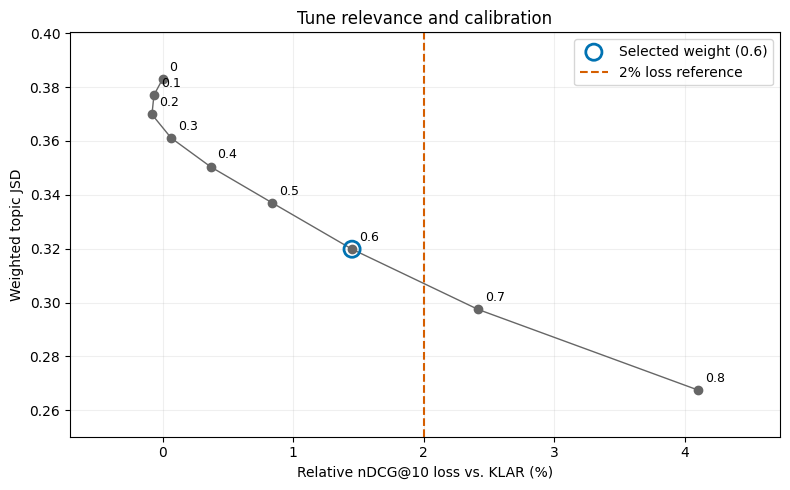

In [21]:
# --- 2.4.1b: Plot the tuning trade-off and mark the recorded weight. ---
import matplotlib.pyplot as plt

tuning_tradeoff_fig, tradeoff_ax = plt.subplots(figsize=(8, 5))
tradeoff_ax.plot(
    tuning_selection_table["ndcg_loss_pct"], tuning_selection_table["weighted_jsd"],
    color="0.4", marker="o", linewidth=1,
)
# Identical operating points share a label so all tested weights remain visible.
for point, weights in tuning_selection_table.groupby(["ndcg_loss_pct", "weighted_jsd"], sort=False):
    tradeoff_ax.annotate(
        ", ".join(f"{weight:g}" for weight in weights.index), point,
        xytext=(5, 6), textcoords="offset points", fontsize=9,
    )
if SELECTED_CALIBRATION_WEIGHT in tuning_selection_table.index:
    selected_point = tuning_selection_table.loc[SELECTED_CALIBRATION_WEIGHT]
    tradeoff_ax.scatter(
        selected_point["ndcg_loss_pct"], selected_point["weighted_jsd"],
        s=135, facecolors="none", edgecolors="#0072B2", linewidth=2,
        label=f"Selected weight ({SELECTED_CALIBRATION_WEIGHT:g})", zorder=3,
    )
tradeoff_ax.axvline(
    NDCG_LOSS_REFERENCE_PCT, color="#D55E00", linestyle="--",
    label=f"{NDCG_LOSS_REFERENCE_PCT:g}% loss reference",
)
tradeoff_ax.set(
    xlabel="Relative nDCG@10 loss vs. KLAR (%)", ylabel="Weighted topic JSD",
    title="Tune relevance and calibration",
)
tradeoff_ax.margins(x=0.15, y=0.15)
tradeoff_ax.legend()

tradeoff_ax.grid(alpha=0.2)
tuning_tradeoff_fig.tight_layout()
plt.show()

#### 2.4.2 Fix the calibration weight for held-out evaluation

Across the initial and expanded tuning sweeps, 0.6 gave the lowest weighted topic mismatch among settings within the 2% relative nDCG@10 loss reference. Weighted JSD fell from 0.3830 to 0.3198 on 328,788 paired Tune impressions, with a 1.452% relative nDCG@10 loss. Weights of 0.7 and 0.8 reduced mismatch further and exceeded the relevance-loss reference. Section 3 uses the recorded weight of 0.6.

### 2.5 Fix the tuning choice for evaluation

#### 2.5.1 Record selected settings and tuning evidence

Carry the chosen weight and its measured Tune results into Test.

In [22]:
# --- 2.5.1: Record selected settings and tuning evidence. ---
if SELECTED_CALIBRATION_WEIGHT not in tuning_selection_table.index:
    raise ValueError("The recorded calibration weight must be in the Tune table.")

selected_tuning_settings = {
    **tuning_settings,
    "calibration_weight": float(SELECTED_CALIBRATION_WEIGHT),
    "selection_method": "manual_tune_review",
    "ndcg_loss_reference_pct": NDCG_LOSS_REFERENCE_PCT,
}
selected_tuning_metrics = tuning_sweep_table.loc[SELECTED_CALIBRATION_WEIGHT].to_dict()
selected_tuning_metrics["ndcg_loss_pct"] = tuning_selection_table.loc[
    SELECTED_CALIBRATION_WEIGHT, "ndcg_loss_pct"
]

#### 2.5.2 Release tuning candidate-level memory

Free the space used by the Tune rankings before loading Test.

In [23]:
# --- 2.5.2: Retain coverage summaries and release tuning candidate-level state. ---
tune_coverage_summary = {
    **tune_history_coverage,
    "eligible_slates": len(tune_eligible_ids),
    "mean_missing_category_mass": tune_topic_coverage["missing_category_mass"].mean(),
    "mean_missing_subcategory_mass": tune_topic_coverage["missing_subcategory_mass"].mean(),
}
del tune_baseline_ranked, tune_baseline_top, tune_slates, tune_profiles
del tune_calibration_prepared, tune_topic_coverage

## 3. Held-out evaluation: before versus after

Compare KLAR and KLAR + calibration on the 15 November Test split.

### 3.1 Use the fixed tuning decision

#### 3.1.1 Copy settings for held-out evaluation

Use the weight of 0.6 and the same ranking settings as Tune.

In [24]:
# --- 3.1.1: Record the held-out settings and score paths. ---
CALIBRATION_EVAL_SCORES_PATH = SCORES_DIR / "klar_calibration.parquet"
evaluation_settings = {
    **selected_tuning_settings,
    "split": "eval",
    "date": "2019-11-15",
    "candidates_path": str(INPUT_SPLITS["eval"]),
    "scores_path": str(EVAL_SCORES_PATH),
    "histories_path": str(HISTORY_PATHS["eval"]),
}

### 3.2 Load evaluation inputs

#### 3.2.1 Load complete processed evaluation candidates and model scores

Load all Test candidates and match each one to its KLAR score.

In [25]:
# --- 3.2.1: Load evaluation candidates and attach original KLAR scores. ---
eval_candidates = load_candidate_split("eval")
eval_scored = load_scored_split("eval", eval_candidates)
del eval_candidates
print(f"Evaluation candidates: {len(eval_scored):,}")

Evaluation candidates: 14,085,557


#### 3.2.2 Load evaluation histories and build topic profiles

Build topic profiles from past clicks. Clicks on the current list are used to measure relevance.

In [26]:
# --- 3.2.2: Load evaluation histories and build topic profiles. ---
eval_impression_ids = pd.Index(eval_scored["impression_id"].unique())
eval_histories = load_impression_histories("eval", eval_impression_ids)
eval_profiles, eval_history_coverage = build_history_profiles(
    eval_histories.reindex(eval_impression_ids), news_topics
)
del eval_histories, eval_impression_ids

### 3.3 Measure the evaluation relevance-only baseline

#### 3.3.1 Build the fixed original-score ranking

Order each Test impression by KLAR score and identify the lists eligible for calibration.

In [27]:
# --- 3.3.1: Build the original held-out ranking and identify eligible slates. ---
eval_baseline_ranked, eval_slates, eval_baseline_top = build_relevance_reference(
    eval_scored, k=evaluation_settings["top_k"], seed=evaluation_settings["seed"],
)
del eval_scored, eval_baseline_top
eval_eligible_ids = eval_slates.index[
    eval_slates["rerank_eligible"] & eval_slates.index.isin(eval_profiles)
]
evaluation_ranks = {"KLAR": eval_baseline_ranked["baseline_rank"].to_numpy()}

#### 3.3.2 Measure relevance overall and on paired impressions

Measure relevance, topic match, and cold exposure before reranking.

In [28]:
# --- 3.3.2: Summarize the held-out KLAR reference. ---
evaluation_summaries = {
    "KLAR": summarize_calibration_ranking(
        eval_baseline_ranked, evaluation_ranks["KLAR"], eval_profiles, eval_eligible_ids,
        k=evaluation_settings["top_k"], seed=evaluation_settings["seed"],
    )
}

### 3.4 Apply the fixed calibration choice and compare evaluation results

#### 3.4.1 Prepare evaluation arrays

Group the candidate scores and topics for each eligible Test impression.

In [29]:
# --- 3.4.1: Prepare the reusable held-out slate arrays. ---
eval_calibration_prepared, eval_topic_coverage = prepare_calibration_slates(
    eval_baseline_ranked, eval_profiles,
)

#### 3.4.2 Rerank once and inspect the resulting top lists

Apply weight 0.6 and count the impressions whose top-10 order changed.

In [30]:
# --- 3.4.2: Apply the tuning-selected weight once. ---
evaluation_ranks["KLAR + calibration"] = run_calibration_ranks(
    eval_baseline_ranked, eval_calibration_prepared,
    evaluation_settings["calibration_weight"], k=evaluation_settings["top_k"],
)
del eval_calibration_prepared

eval_calibrated_ranks = evaluation_ranks["KLAR + calibration"]
eval_changed_topk = (
    (eval_calibrated_ranks <= evaluation_settings["top_k"])
    & (eval_calibrated_ranks != evaluation_ranks["KLAR"])
)
eval_changed_topk_count = eval_baseline_ranked.loc[eval_changed_topk, "impression_id"].nunique()
print(f"Eligible evaluation impressions: {len(eval_eligible_ids):,}")
print(f"Impressions with a changed top-k order: {eval_changed_topk_count:,}")

Eligible evaluation impressions: 273,671
Impressions with a changed top-k order: 270,657


#### 3.4.3 Export the full evaluation ranking for Step 6

Save `klar_calibration.parquet` for Step 6. Each row gives the impression ID, article ID, and negative final rank, so higher scores come first.

In [31]:
# --- 3.4.3: Validate and export the complete evaluation ranking. ---
from pyarrow.parquet import ParquetFile


def validate_rank_permutations(impression_ids, ranks):
    """Require a permutation of 1 through the slate size for each impression."""
    if not np.isfinite(ranks).all() or (ranks < 1).any() or not np.equal(ranks, np.floor(ranks)).all():
        raise ValueError("Final ranks must be finite positive integers.")
    order = pd.DataFrame({"impression_id": impression_ids.to_numpy(), "rank": ranks})
    largest = order.groupby("impression_id", sort=False)["rank"].agg(["size", "max"])
    if not largest["size"].eq(largest["max"]).all() or order.duplicated().any():
        raise ValueError("Final ranks must be a complete permutation within each impression.")


def export_calibration_scores(ranked, final_ranks, path):
    """Write the rank-derived scores and verify the persisted candidate rows."""
    export = ranked[KEY_COLUMNS].copy()
    if export.duplicated().any():
        raise ValueError("Evaluation candidate keys must be unique.")
    validate_rank_permutations(export["impression_id"], final_ranks)
    export["score"] = -final_ranks
    path.parent.mkdir(parents=True, exist_ok=True)
    export.to_parquet(path, index=False, engine="pyarrow")

    with ParquetFile(path) as parquet:
        if parquet.schema_arrow.names != KEY_COLUMNS + ["score"] or parquet.metadata.num_rows != len(export):
            raise ValueError("Saved evaluation ranking has an unexpected schema or row count.")
        offset = 0
        for batch in parquet.iter_batches():
            saved = batch.to_pandas()
            expected = export.iloc[offset:offset + len(saved)]
            for column in export.columns:
                np.testing.assert_array_equal(saved[column].to_numpy(), expected[column].to_numpy())
            offset += len(saved)
    return {"path": str(path), "rows": len(export), "score": "negative final rank"}


evaluation_score_export = export_calibration_scores(
    eval_baseline_ranked, eval_calibrated_ranks, CALIBRATION_EVAL_SCORES_PATH,
)
print(f"Saved {evaluation_score_export['rows']:,} candidate scores to {CALIBRATION_EVAL_SCORES_PATH}")

Saved 14,085,557 candidate scores to /content/drive/MyDrive/BT4222_Project/data/scores/klar_calibration.parquet


#### 3.4.4 Measure relevance, topic mismatch, and cold exposure after reranking

Measure the calibrated ranking using the same impression groups as KLAR.

In [32]:
# --- 3.4.4: Measure the calibrated KLAR ranking. ---
evaluation_summaries["KLAR + calibration"] = summarize_calibration_ranking(
    eval_baseline_ranked, evaluation_ranks["KLAR + calibration"], eval_profiles, eval_eligible_ids,
    k=evaluation_settings["top_k"], seed=evaluation_settings["seed"],
)

### 3.5 Summarize held-out metrics and prepare reporting inputs

Compare the two rankings and show how many impressions had usable histories or could be reranked.

In [33]:
# --- 3.5: Build compact evaluation tables and coverage summaries. ---
evaluation_results = pd.DataFrame.from_dict(evaluation_summaries, orient="index").rename_axis("method")
eval_population_columns = [
    "overall_relevance_impressions", "overall_full_lists", "paired_impressions",
]
eval_metric_values = evaluation_results.drop(columns=eval_population_columns)
evaluation_changes = eval_metric_values.subtract(eval_metric_values.loc["KLAR"], axis="columns")
eval_coverage_summary = {
    **eval_history_coverage,
    "eligible_slates": len(eval_eligible_ids),
    "fallback_slates": len(eval_slates) - len(eval_eligible_ids),
    "changed_topk_slates": eval_changed_topk_count,
    "mean_missing_category_mass": eval_topic_coverage["missing_category_mass"].mean(),
    "mean_missing_subcategory_mass": eval_topic_coverage["missing_subcategory_mass"].mean(),
}

print(evaluation_results.to_string(float_format=lambda value: f"{value:.4f}"))
print()
print(pd.Series(eval_coverage_summary).to_string())

                    overall_mrr  overall_ndcg@5  overall_ndcg@10  paired_mrr  paired_ndcg@5  paired_ndcg@10  overall_relevance_impressions  overall_full_lists  overall_cold_share  paired_impressions  paired_cold_share  category_jsd  subcategory_jsd  weighted_jsd
method                                                                                                                                                                                                                                                                
KLAR                     0.2987          0.3286           0.3950      0.2219         0.2362          0.3107                         376471              294491              0.2196              273671             0.2159        0.3327           0.6187        0.4042
KLAR + calibration       0.3015          0.3310           0.3979      0.2257         0.2396          0.3146                         376471              294491              0.2228              273671             

### 3.6 Export compact evaluation summaries

Save the Test tables and run details under `step5_calibration_evaluation_summary`.

In [34]:
# --- 3.6: Save the evaluation tables and run metadata. ---
import json

evaluation_summary_dir = Path(config.OUTPUT_DIR) / "step5_calibration_evaluation_summary"
evaluation_summary_dir.mkdir(parents=True, exist_ok=True)
evaluation_results.to_csv(evaluation_summary_dir / "metrics.csv")
evaluation_changes.to_csv(evaluation_summary_dir / "changes_vs_klar.csv")


def json_metrics(values):
    """Use JSON null for unavailable scalar measurements."""
    return {key: (None if pd.isna(value) else value) for key, value in values.items()}


evaluation_run_metadata = {
    "tuning_settings": selected_tuning_settings,
    "selected_tuning_metrics": json_metrics(selected_tuning_metrics),
    "evaluation_settings": evaluation_settings,
    "tuning_coverage": json_metrics(tune_coverage_summary),
    "evaluation_coverage": json_metrics(eval_coverage_summary),
    "methods": evaluation_results.index.tolist(),
    "metric_populations": {
        "overall_relevance": "All impressions with at least one clicked and one unclicked candidate.",
        "overall_cold_share": "All full top-k lists.",
        "paired": "Impressions with usable history, more than top-k candidates, and valid relevance labels.",
    },
    "step6_handoff": evaluation_score_export,
}
with (evaluation_summary_dir / "run.json").open("w", encoding="utf-8") as summary_file:
    json.dump(evaluation_run_metadata, summary_file, indent=2, allow_nan=False)
    summary_file.write("\n")

print(f"Saved evaluation tables and run metadata to {evaluation_summary_dir}")

Saved evaluation tables and run metadata to /content/drive/MyDrive/BT4222_Project/outputs/step5_calibration_evaluation_summary


## 4. Illustrative slate and results summary

One Test slate shows how calibration changes the topic mix in the top 10.

### 4.1 Prepare presentation settings and output paths

Set the output locations for the tuning figure and result tables.

In [35]:
# --- 4.1: Define the report output path and tuning export view. ---
report_methods = evaluation_results.index.tolist()
report_dir = Path(config.OUTPUT_DIR) / "step5_calibration_report"
report_tuning_view = tuning_sweep_table.join(tuning_selection_table[["ndcg_loss_pct"]])

### 4.2 Inspect a reproducible illustrative recommendation slate

#### 4.2.1 Select an example independently of its outcome

The example is selected from eligible impressions with a fixed seed, before comparing the two rankings.

In [36]:
# --- 4.2.1: Select one seeded eligible impression. ---
example_pool = pd.Index(eval_eligible_ids).sort_values()
example_ids = np.random.default_rng(evaluation_settings["seed"]).choice(
    example_pool, size=min(1, len(example_pool)), replace=False,
).tolist()
example_roles = dict.fromkeys(example_ids, "Seeded eligible example")

#### 4.2.2 Collect article movements and compare topic distributions

Show titles and ranks for articles in either top 10. Compare topic shares in the user's history, the full candidate list, and the two top-10 lists.

In [37]:
# --- 4.2.2: Assemble article movements, topic shares, and coverage. ---
from IPython.display import display

example_k = evaluation_settings["top_k"]
example_positions = np.flatnonzero(eval_baseline_ranked["impression_id"].isin(example_ids).to_numpy())
example_candidates = eval_baseline_ranked.iloc[example_positions][KEY_COLUMNS + TOPIC_COLUMNS + [
    "score", "label", COLD_COLUMN,
]].copy()
example_candidates[TOPIC_COLUMNS] = normalize_topics(example_candidates)
example_rank_columns = {
    "KLAR": "klar_rank", "KLAR + calibration": "calibration_rank",
}
for method, rank_column in example_rank_columns.items():
    example_candidates[rank_column] = evaluation_ranks[method][example_positions]

shown = example_candidates[list(example_rank_columns.values())].le(example_k).any(axis=1)
example_articles = example_candidates.loc[shown].copy()
if not example_articles.empty:
    titles = pd.read_parquet(
        NEWS_METADATA_PATH, columns=["news_id", "title"], engine="pyarrow",
        filters=[("news_id", "in", example_articles["news_id"].unique().tolist())],
    ).set_index("news_id")["title"]
    example_articles["title"] = example_articles["news_id"].map(titles)
else:
    example_articles["title"] = pd.Series(dtype=str)
example_articles["movement"] = np.select(
    [
        example_articles["klar_rank"].gt(example_k) & example_articles["calibration_rank"].le(example_k),
        example_articles["klar_rank"].le(example_k) & example_articles["calibration_rank"].gt(example_k),
        example_articles["klar_rank"].le(example_k) & example_articles["calibration_rank"].le(example_k),
    ],
    ["entered", "exited", "retained"], default="outside both",
)
example_articles = example_articles[KEY_COLUMNS + ["title"] + TOPIC_COLUMNS + [
    "score", "label", COLD_COLUMN, *example_rank_columns.values(), "movement",
]].sort_values(["impression_id", "calibration_rank"])

example_topic_rows = []
for impression_id, candidates in example_candidates.groupby("impression_id", sort=False):
    category_history, subcategory_history = eval_profiles[impression_id]
    sources = {
        "Candidates": candidates,
        **{method: candidates.loc[candidates[rank_col].le(example_k)]
           for method, rank_col in example_rank_columns.items()},
    }
    distributions = {
        "category": {
            "History": category_history,
            **{name: topic_distribution(frame["category"]) for name, frame in sources.items()},
        },
        "subcategory": {
            "History": subcategory_history,
            **{name: topic_distribution(frame[TOPIC_COLUMNS].itertuples(index=False, name=None))
               for name, frame in sources.items()},
        },
    }
    for level, by_source in distributions.items():
        topics = sorted({topic for distribution in by_source.values() for topic in distribution})
        for topic in topics:
            label = " / ".join(topic) if level == "subcategory" else topic
            example_topic_rows.append({
                "impression_id": impression_id, "level": level, "topic": label,
                **{name: distribution.get(topic, 0.0) for name, distribution in by_source.items()},
            })

example_topic_shares = pd.DataFrame(example_topic_rows, columns=[
    "impression_id", "level", "topic", "History", "Candidates", *report_methods,
])
example_coverage = eval_topic_coverage.set_index("impression_id").reindex(example_ids)
example_coverage.insert(0, "selection", pd.Series(example_roles, dtype=str))

#### 4.2.3 Inspect the selected recommendation slate

The tables show which articles moved and how the topic mix changed.

In [38]:
# --- 4.2.3: Display the seeded example with compact topic views. ---
display(example_coverage.round(4))
for impression_id in example_ids:
    print(f"Impression {impression_id}")
    display(example_articles.loc[example_articles["impression_id"].eq(impression_id)])
    example_shares = example_topic_shares.loc[example_topic_shares["impression_id"].eq(impression_id)]
    for level, frame in example_shares.groupby("level", sort=False):
        visible = frame[["History", *report_methods]].max(axis=1).gt(0)
        display(frame.loc[visible].drop(columns=["impression_id", "level"])
                .sort_values("History", ascending=False, kind="stable").round(3))

,selection,missing_category_mass,missing_subcategory_mass
impression_id,,,
130163,Seeded eligible example,0.0115,0.2184


Impression 130163


,impression_id,news_id,title,category,subcategory,score,label,cold_article,klar_rank,calibration_rank,movement
1263030,130163,N123833,Trump defends Yovanovitch attack: 'I have free...,news,newspolitics,1.643847,1,1,2,1,retained
1263038,130163,N30206,Cows swept away by Hurricane Dorian found aliv...,lifestyle,lifestylebuzz,1.976587,0,0,1,2,retained
1263051,130163,N89764,Report: Police investigating woman's death aft...,sports,football_nfl,1.282370,0,1,3,3,retained
1263045,130163,N52464,4 takeaways from Marie Yovanovitch's testimony,news,newspolitics,0.743779,0,0,9,4,retained
1263028,130163,N121267,Meghan Markle's Lawyers Debunk Multiple False ...,lifestyle,lifestyleroyals,0.811542,0,0,5,5,retained
1263046,130163,N56590,Chris Evans' Hilarious Reason Why He Continues...,entertainment,video,0.755926,0,1,8,6,retained
1263033,130163,N129416,"Taylor Swift Rep Hits Back at Big Machine, Cla...",music,musicnews,0.651995,0,0,11,7,entered
1263035,130163,N21018,3 Indiana judges suspended after a night of dr...,news,newsus,0.432930,0,1,19,8,entered
1263037,130163,N29160,Opinion: Colin Kaepernick is about to get what...,sports,football_nfl,0.763565,0,0,7,9,retained
1263032,130163,N126696,Maze of tunnels reveals remains of ancient Jer...,travel,travelnews,0.884932,0,0,4,10,retained


,topic,History,Candidates,KLAR,KLAR + calibration
8,news,0.517,0.156,0.2,0.3
5,lifestyle,0.184,0.156,0.3,0.2
9,sports,0.080,0.156,0.2,0.2
1,entertainment,0.057,0.062,0.1,0.1
6,movies,0.057,0.094,0.0,0.0
7,music,0.057,0.031,0.0,0.1
11,tv,0.023,0.062,0.0,0.0
2,finance,0.011,0.094,0.0,0.0
12,video,0.011,0.000,0.0,0.0
10,travel,0.000,0.031,0.1,0.1


,topic,History,Candidates,KLAR,KLAR + calibration
37,news / newspolitics,0.276,0.094,0.2,0.2
38,news / newsus,0.149,0.031,0.0,0.1
23,lifestyle / lifestylebuzz,0.092,0.031,0.1,0.1
36,news / newscrime,0.069,0.031,0.0,0.0
31,movies / movies-celebrity,0.057,0.000,0.0,0.0
15,entertainment / celebrity,0.046,0.031,0.0,0.0
26,lifestyle / lifestyleroyals,0.046,0.031,0.1,0.1
33,music / music-celebrity,0.034,0.000,0.0,0.0
43,sports / football_nfl,0.034,0.094,0.2,0.2
24,lifestyle / lifestylecelebstyle,0.023,0.000,0.0,0.0


### 4.3 Export results and the Tune figure

Save the Tune and Test tables, example slate, and tuning figure.

In [39]:
# --- 4.3: Save the result tables, example slate, and Tune figure. ---
report_dir.mkdir(parents=True, exist_ok=True)
report_tables = {
    Path(config.OUTPUT_DIR) / "results_step5_calibration_tuning.csv": (report_tuning_view, True),
    Path(config.OUTPUT_DIR) / "results_step5_calibration_eval.csv": (evaluation_results, True),
    report_dir / "tuning_selection.csv": (tuning_selection_table, True),
    report_dir / "example_coverage.csv": (example_coverage, True),
    report_dir / "example_articles.csv": (example_articles, False),
    report_dir / "example_topic_shares.csv": (example_topic_shares, False),
}
for destination, (table, keep_index) in report_tables.items():
    table.to_csv(destination, index=keep_index)

tune_figure_paths = [report_dir / f"tune_tradeoff.{extension}" for extension in ("png", "pdf")]
for destination in tune_figure_paths:
    tuning_tradeoff_fig.savefig(destination, dpi=180, bbox_inches="tight")

print(f"Saved results to {Path(config.OUTPUT_DIR)} and report files to {report_dir}")

Saved results to /content/drive/MyDrive/BT4222_Project/outputs and report files to /content/drive/MyDrive/BT4222_Project/outputs/step5_calibration_report


### 4.4 Slate calibration results report

**Model** KLAR v1 | **Held-out date** 15 November 2019 | **Calibration weight** 0.6 | **Top k** 10 | **Seed** 42

#### Tuning decision

Across the initial and expanded Tune sweeps, 0.6 gave the lowest weighted JSD within the 2% relative nDCG@10 loss reference. On 328,788 paired Tune impressions, weighted JSD fell from 0.3830 to 0.3198 and nDCG@10 fell from 0.3295 to 0.3247, a 1.45% relative loss. The weight was fixed before the 0.6 held-out run.

#### Held-out results

Overall nDCG@10 rose from 0.3950 to 0.3979. On paired impressions it rose from 0.3107 to 0.3146, while category JSD fell from 0.3327 to 0.2570 and subcategory JSD fell from 0.6187 to 0.5694. Weighted JSD fell from 0.4042 to 0.3351.

Overall relevance covers 376,471 impressions. Overall cold exposure covers 294,491 complete top-10 lists. The paired population contains 273,671 eligible impressions with usable histories and valid relevance labels. Calibration reduced weighted topic mismatch by 17.1% and increased paired nDCG@10 by 0.0039. Paired cold exposure rose by 0.35 percentage points.

#### Interpretation

The top-10 order changed on 270,657 eligible impressions. On average, the available articles were missing topics that accounted for 8.7% of past clicks by category and 41.6% by subcategory. This limits how closely the top 10 can match the finer details of a user's reading history. Section 4.2 illustrates how the displayed topic mix changes on one seeded slate.